# Lesson 10: Linear Regression with One Regressor
**ECON 5105 · Mathematics and Statistics for Economists · Fall 2026**

A hands-on companion to Qianwei Shen's *Lesson 10* (November 12, 2026).

**Question:** How are student-teacher ratios (STR) related to test scores?

We will compute OLS by hand, check it with Python, interpret fitted values and residuals, measure fit, investigate causal assumptions and outliers, simulate sampling uncertainty, and evaluate predictions on new data.

**Data:** All district-level observations below are **simulated**, not the California school data. The coefficients and noise scale are inspired by the lecture; the simulated estimates will differ from its empirical estimates. A separate arithmetic example reproduces the lecture's rounded numbers.

**Run:** Python 3.10+; install `numpy pandas matplotlib scipy statsmodels ipykernel` if needed (for example, `%pip install numpy pandas matplotlib scipy statsmodels ipykernel` in a new cell), select a Python kernel, then **Restart Kernel and Run All**. No downloads, API keys, or external data files are required. Random seeds make the demonstrations reproducible.

## Road map
1. Population model and simulated sample (slides 5–8)
2. OLS mechanics, interpretation, predictions, and residuals (slides 9–21)
3. R², SER, RMSE, and regression output (slides 22–31)
4. Causal assumptions, confounding, and outliers (slides 32–40)
5. Sampling distributions and error variance (slides 41–54)
6. Out-of-sample prediction (slides 55–57)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from IPython.display import display

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
pd.options.display.float_format = '{:,.3f}'.format
SEED = 5105

Matplotlib is building the font cache; this may take a moment.


## 1. Population model versus one observed sample
$$Y_i=\beta_0+\beta_1X_i+u_i.$$
Here $Y$ is a district's average test score and $X$ is students per teacher. The error $u$ includes everything else affecting scores. It need not be a recording mistake.

We choose $\beta_0=698.9$, $\beta_1=-2.28$, and $u\sim N(0,18.6^2)$ independently of $X$. In this **constructed** population, $E(u\mid X)=0$. We know the true errors only because we generated the data; real data usually reveal residuals, not population errors.

,STR,TestScore
0,23.525,636.676
1,14.994,683.823
2,21.931,657.785
3,25.090,649.158
4,18.806,664.197


,STR,TestScore
count,420.000,420.000
mean,19.937,652.214
std,3.426,20.477
min,14.046,591.260
25%,17.015,638.973
50%,20.174,652.865
75%,22.676,665.556
max,25.979,713.549


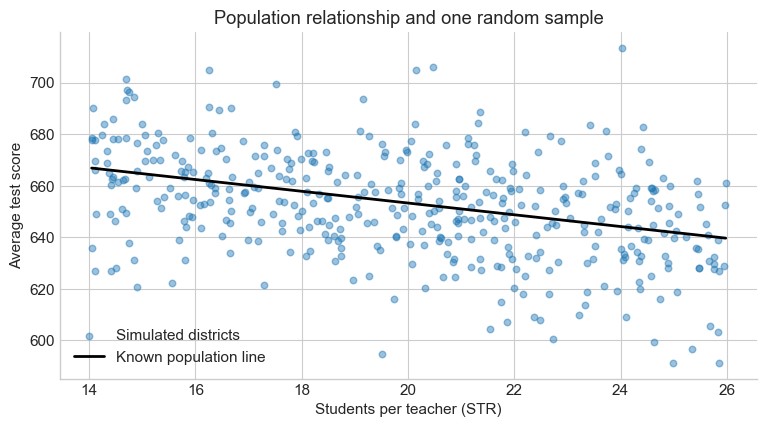

In [2]:
rng = np.random.default_rng(SEED)
n = 420
beta0, beta1, sigma = 698.9, -2.28, 18.6
x = rng.uniform(14, 26, n)
u = rng.normal(0, sigma, n)
y = beta0 + beta1*x + u
districts = pd.DataFrame({'STR': x, 'TestScore': y})
display(districts.head())
display(districts.describe())
plt.scatter(x, y, alpha=.45, s=22, label='Simulated districts')
grid = np.linspace(x.min(), x.max(), 150)
plt.plot(grid, beta0 + beta1*grid, color='black', lw=2, label='Known population line')
plt.xlabel('Students per teacher (STR)'); plt.ylabel('Average test score')
plt.title('Population relationship and one random sample'); plt.legend(); plt.show()

## 2. OLS from scratch and with statsmodels
OLS minimizes $\sum_i(Y_i-b_0-b_1X_i)^2$. Its solution is
$$\hat\beta_1=\frac{\sum_i(X_i-\bar X)(Y_i-\bar Y)}{\sum_i(X_i-\bar X)^2},\qquad
\hat\beta_0=\bar Y-\hat\beta_1\bar X.$$
The slope also equals $s_{XY}/s_X^2=r_{XY}s_Y/s_X$. Variation in $X$ is necessary to identify the slope.

In [3]:
def ols_by_hand(x_values, y_values):
    x_values, y_values = np.asarray(x_values), np.asarray(y_values)
    xc = x_values - x_values.mean()
    sxx = xc @ xc
    if sxx <= 0:
        raise ValueError('OLS slope requires variation in X.')
    b1 = (xc @ (y_values - y_values.mean())) / sxx
    b0 = y_values.mean() - b1*x_values.mean()
    return b0, b1

b0, b1 = ols_by_hand(x, y)
X = sm.add_constant(districts[['STR']])
model = sm.OLS(districts['TestScore'], X).fit()
matrix_coef = np.linalg.lstsq(X, y, rcond=None)[0]
corr_slope = np.corrcoef(x, y)[0, 1]*y.std(ddof=1)/x.std(ddof=1)
np.testing.assert_allclose([b0, b1], model.params, rtol=1e-10)
np.testing.assert_allclose([b0, b1], matrix_coef, rtol=1e-10)
np.testing.assert_allclose(b1, corr_slope)
display(pd.DataFrame({'Population': [beta0, beta1], 'By hand': [b0, b1],
                      'statsmodels': model.params.to_numpy()}, index=['Intercept', 'STR slope']))

,Population,By hand,statsmodels
Intercept,698.900,700.405,700.405
STR slope,-2.280,-2.417,-2.417


### Fitted values, residuals, and interpretation
$\hat Y_i=\hat\beta_0+\hat\beta_1X_i$ and $\hat u_i=Y_i-\hat Y_i$. With an intercept, residuals sum to zero, are orthogonal to $X$, and the fitted line passes through $(\bar X,\bar Y)$.

The slope is the fitted score difference associated with one additional student per teacher. The intercept predicts the score at STR = 0, outside our data range; it has no useful literal school interpretation. A fitted change is causal only if the relevant causal assumptions hold.

Fitted line: TestScore = 700.41 -2.42 × STR
Fitted score change from STR 25 to 20: 12.09 points


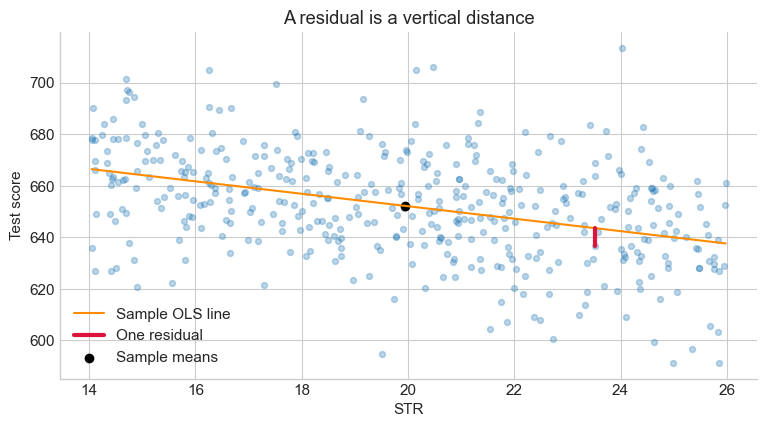

,Actual,Fitted,Residual,True simulated error
0,636.676,643.541,-6.864,-8.587
1,683.823,664.161,19.662,19.110
2,657.785,647.395,10.390,8.887
3,649.158,639.758,9.400,7.463
4,664.197,654.947,9.250,8.175


In [4]:
yhat = b0 + b1*x
resid = y - yhat
np.testing.assert_allclose(resid.sum(), 0, atol=1e-8)
np.testing.assert_allclose(x @ resid, 0, atol=1e-7)
np.testing.assert_allclose(b0 + b1*x.mean(), y.mean())
print(f'Fitted line: TestScore = {b0:.2f} {b1:+.2f} × STR')
print(f'Fitted score change from STR 25 to 20: {b1*(20-25):.2f} points')
i = 0
plt.scatter(x, y, alpha=.3, s=18)
plt.plot(grid, b0+b1*grid, color='darkorange', label='Sample OLS line')
plt.plot([x[i], x[i]], [yhat[i], y[i]], color='crimson', lw=3, label='One residual')
plt.scatter([x.mean()], [y.mean()], color='black', label='Sample means')
plt.xlabel('STR'); plt.ylabel('Test score'); plt.title('A residual is a vertical distance')
plt.legend(); plt.show()
display(pd.DataFrame({'Actual': y[:5], 'Fitted': yhat[:5], 'Residual': resid[:5],
                      'True simulated error': u[:5]}))

### Lecture arithmetic: Antelope, CA (slide 21)
Use the lecture's **rounded** empirical line, not the simulated model. The slide's reported prediction and residual are approximate.

In [5]:
lecture_prediction = 698.9 - 2.28*19.33
print(f'Rounded lecture line predicts: {lecture_prediction:.3f}')
print(f'Residual for observed score 657.8: {657.8-lecture_prediction:.3f}')
print('These are approximately 654.8 and 3.0, as in the lecture.')

Rounded lecture line predicts: 654.828
Residual for observed score 657.8: 2.972
These are approximately 654.8 and 3.0, as in the lecture.


## 3. Measures of fit
Define $TSS=\sum(Y_i-\bar Y)^2$, $ESS=\sum(\hat Y_i-\bar Y)^2$, and $RSS=\sum\hat u_i^2$. With an intercept, $TSS=ESS+RSS$.

$$R^2=1-\frac{RSS}{TSS},\qquad SER=\sqrt{\frac{RSS}{n-2}},\qquad RMSE=\sqrt{\frac{RSS}{n}}.$$

Some sources call residual sum of squares **SSR**, so check the definition. R² has no units; SER and RMSE have score units. The two fitted coefficients explain the $n-2$ degrees of freedom. R² compares in-sample squared error against predicting the sample mean; it neither establishes causation nor guarantees good future predictions.

In [6]:
tss = np.sum((y-y.mean())**2)
rss = np.sum(resid**2)
ess = np.sum((yhat-y.mean())**2)
r2, ser, rmse = 1-rss/tss, np.sqrt(rss/(n-2)), np.sqrt(rss/n)
np.testing.assert_allclose(tss, ess+rss)
np.testing.assert_allclose(r2, model.rsquared)
np.testing.assert_allclose(ser, np.sqrt(model.mse_resid))
np.testing.assert_allclose(r2, np.corrcoef(x, y)[0, 1]**2)
display(pd.Series({'TSS': tss, 'ESS': ess, 'RSS': rss, 'R²': r2,
                   'SER': ser, 'In-sample RMSE': rmse}, name='Fit measures'))
print(model.summary())

TSS              175,691.095
ESS               28,729.487
RSS              146,961.607
R²                     0.164
SER                   18.751
In-sample RMSE        18.706
Name: Fit measures, dtype: float64

                            OLS Regression Results                            
Dep. Variable:              TestScore   R-squared:                       0.164
Model:                            OLS   Adj. R-squared:                  0.162
Method:                 Least Squares   F-statistic:                     81.71
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           5.92e-18
Time:                        10:32:06   Log-Likelihood:                -1826.1
No. Observations:                 420   AIC:                             3656.
Df Residuals:                     418   BIC:                             3664.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        700.4055      5.409    129.486      0.0

**Reading the output:** `coef` contains the fitted intercept and slope; `std err` measures their sampling uncertainty; `t`, `P>|t|`, and the interval columns support tests and confidence intervals. These default standard errors assume homoskedastic errors. R-squared measures fit, and `No. Observations` is the sample size.

**Discuss:** Why might class size be policy relevant even when R² is low? A fitted five-student change can be substantial relative to score variation, but an observational slope still needs a causal identification argument.

## 4. Causal assumptions: see what confounding does
For a causal interpretation, the lecture requires (1) $E(u\mid X)=0$, (2) i.i.d. sampling, and (3) finite fourth moments, with nonzero variation in $X$.

An example: family resources $Z$ increase scores and are associated with lower STR. If we regress scores on STR alone, $\gamma Z$ enters the error. The omitted-variable term is $\gamma\,\operatorname{Cov}(X,Z)/\operatorname{Var}(X)$.

Below the **true causal slope is -2.28 in both scenarios**. We change only how STR is assigned. Random assignment breaks the link between STR and resources. This is a simulation of identification, not evidence about actual schools.

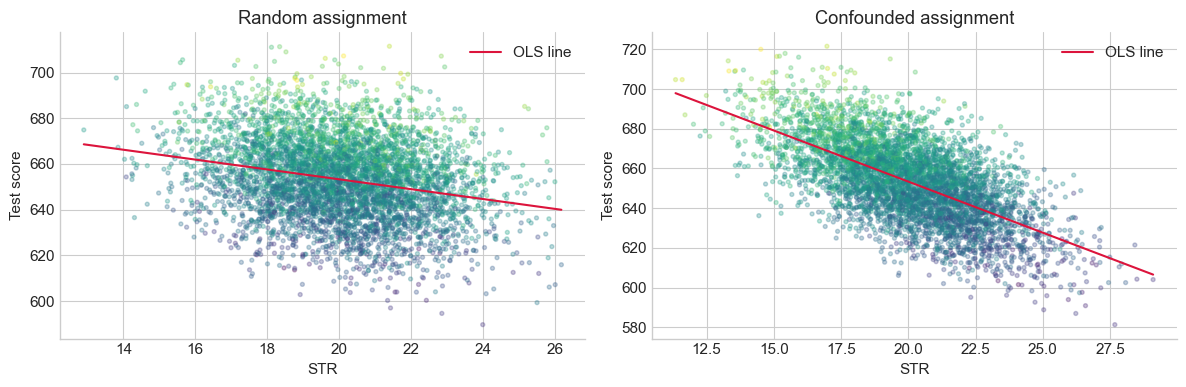

,Assignment,True causal slope,OLS slope,Sample omitted-variable term
0,Random assignment,-2.280,-2.156,0.028
1,Confounded assignment,-2.280,-5.152,-2.883


In [7]:
conf_rng = np.random.default_rng(SEED+1)
n_conf = 5000
resources = conf_rng.normal(size=n_conf)
assignment_noise = conf_rng.normal(size=n_conf)
epsilon = conf_rng.normal(0, 12, n_conf)
gamma = 12
scenarios = {'Random assignment': 20+2*assignment_noise,
             'Confounded assignment': 20-1.5*resources+2*assignment_noise}
rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, xc) in zip(axes, scenarios.items()):
    yc = beta0+beta1*xc+gamma*resources+epsilon
    c0, c1 = ols_by_hand(xc, yc)
    ovb = gamma*np.cov(xc, resources, ddof=1)[0, 1]/np.var(xc, ddof=1)
    rows.append({'Assignment': name, 'True causal slope': beta1,
                 'OLS slope': c1, 'Sample omitted-variable term': ovb})
    ax.scatter(xc, yc, c=resources, cmap='viridis', alpha=.3, s=8)
    gx = np.linspace(xc.min(), xc.max(), 100)
    ax.plot(gx, c0+c1*gx, color='crimson', label='OLS line')
    ax.set(title=name, xlabel='STR', ylabel='Test score'); ax.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows))

### Outliers and influential observations
Finite fourth moments do not guarantee the absence of influential points in a finite sample. An extreme STR paired with an unusual score can pull the fitted line. Investigate data quality, the target population, and sensitivity before deciding whether exclusion is justified. Do not remove a point merely because it changes your preferred answer.

Independence also needs a study-design argument: students within schools and repeated observations over time may be dependent. A scatterplot cannot establish i.i.d. sampling or conditional mean independence.

Original slope: -2.417; slope after adding one artificial point: -1.477


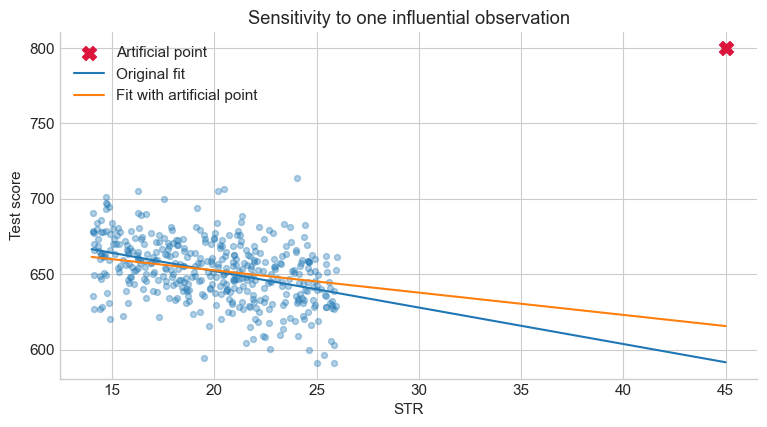

In [8]:
x_out = np.append(x, 45.)
y_out = np.append(y, 800.)
o0, o1 = ols_by_hand(x_out, y_out)
print(f'Original slope: {b1:.3f}; slope after adding one artificial point: {o1:.3f}')
plt.scatter(x, y, alpha=.35, s=18)
plt.scatter([45], [800], color='crimson', marker='X', s=100, label='Artificial point')
gout = np.linspace(14, 45, 150)
plt.plot(gout, b0+b1*gout, label='Original fit')
plt.plot(gout, o0+o1*gout, label='Fit with artificial point')
plt.xlabel('STR'); plt.ylabel('Test score'); plt.title('Sensitivity to one influential observation')
plt.legend(); plt.show()

## 5. Sampling distributions: repeat the experiment
Each repetition draws a **new sample**, not a new regression on the same data. Under the assumptions, OLS is unbiased and consistent, and its sampling distribution becomes approximately normal as sample size grows. Normally distributed errors are not required for these large-sample results.

For homoskedastic errors,
$$\operatorname{Var}(\hat\beta_1\mid X)=\frac{\sigma_u^2}{\sum_i(X_i-\bar X)^2},\qquad
\operatorname{Var}(\hat\beta_1)\approx\frac{\sigma_u^2}{n\operatorname{Var}(X)}.$$
Thus more observations or more variation in $X$ improve precision; more error noise reduces it. The second formula is a large-sample approximation, not a general finite-sample unconditional identity.

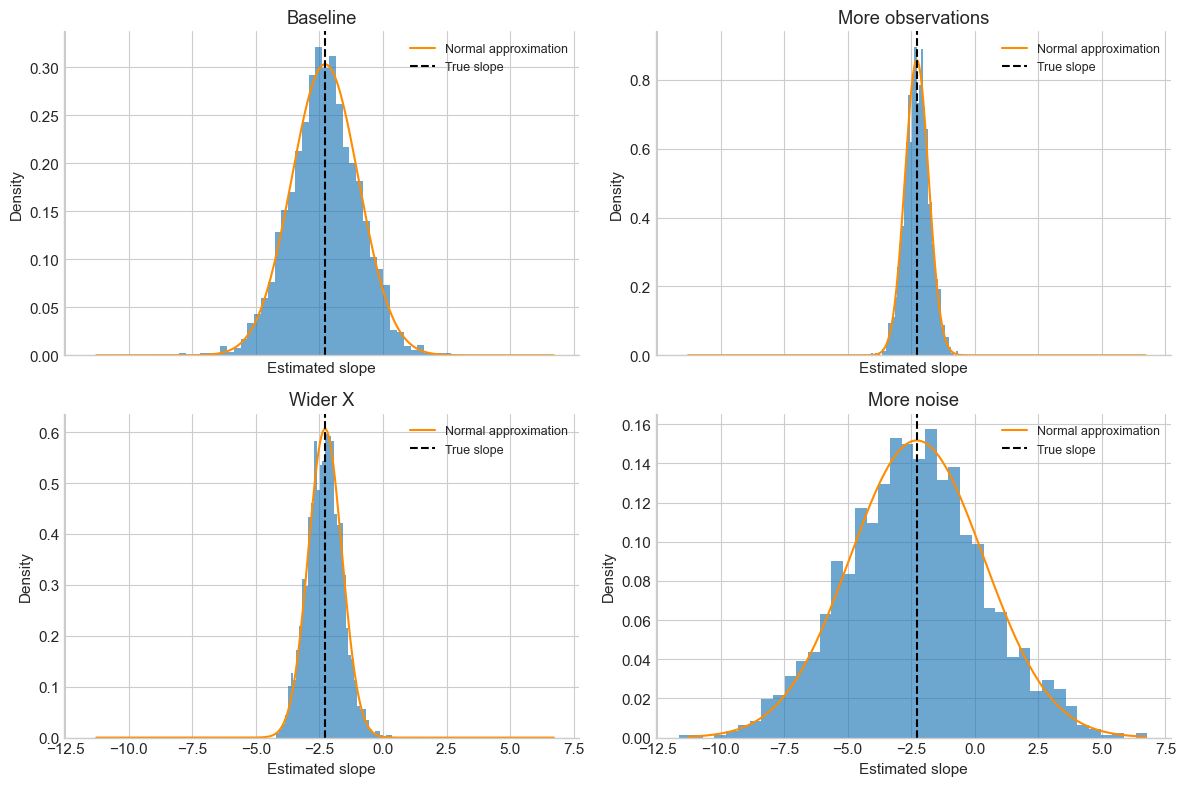

,Scenario,n,X SD,Error SD,Mean slope,Empirical slope SD,Approximate SD
0,Baseline,50,2,18.600,-2.307,1.346,1.315
1,More observations,400,2,18.600,-2.267,0.478,0.465
2,Wider X,50,4,18.600,-2.294,0.678,0.658
3,More noise,50,2,37.200,-2.361,2.696,2.630


In [9]:
def simulate_slopes(sample_n, x_sd, noise_sd, repetitions=2000, seed=0):
    generator = np.random.default_rng(seed)
    xx = generator.normal(20, x_sd, size=(repetitions, sample_n))
    uu = generator.normal(0, noise_sd, size=xx.shape)
    yy = beta0 + beta1*xx + uu
    centered = xx-xx.mean(axis=1, keepdims=True)
    return np.sum(centered*(yy-yy.mean(axis=1, keepdims=True)), axis=1)/np.sum(centered**2, axis=1)

settings = [('Baseline', 50, 2, 18.6), ('More observations', 400, 2, 18.6),
            ('Wider X', 50, 4, 18.6), ('More noise', 50, 2, 37.2)]
sampling_rows = []
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for j, (ax, (name, size, spread, noise)) in enumerate(zip(axes.flat, settings)):
    slopes = simulate_slopes(size, spread, noise, seed=SEED+10+j)
    approx_sd = noise/(np.sqrt(size)*spread)
    sampling_rows.append({'Scenario': name, 'n': size, 'X SD': spread,
                         'Error SD': noise, 'Mean slope': slopes.mean(),
                         'Empirical slope SD': slopes.std(ddof=1), 'Approximate SD': approx_sd})
    ax.hist(slopes, bins=40, density=True, alpha=.65)
    g = np.linspace(beta1-9, beta1+9, 300)
    ax.plot(g, stats.norm.pdf(g, beta1, approx_sd), color='darkorange', label='Normal approximation')
    ax.axvline(beta1, color='black', linestyle='--', label='True slope')
    ax.set(title=name, xlabel='Estimated slope', ylabel='Density'); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()
display(pd.DataFrame(sampling_rows))

### Heteroskedasticity and robust uncertainty
Constant conditional error variance is an **additional** assumption, separate from the lecture's three least-squares assumptions. Under heteroskedasticity the general asymptotic variance is
$$\operatorname{Avar}(\hat\beta_1)=\frac{E[(X-\mu_X)^2u^2]}{n\operatorname{Var}(X)^2}.$$
The simpler $\sigma_u^2/[n\operatorname{Var}(X)]$ expression requires homoskedasticity.

We now generate mean-zero errors whose variance rises with STR. HC1 robust standard errors change uncertainty estimates, not OLS coefficients. They do not fix confounding or dependence between observations.

,Coefficient,Conventional SE,HC1 robust SE
Intercept,705.070,5.680,5.432
STR,-2.655,0.281,0.308


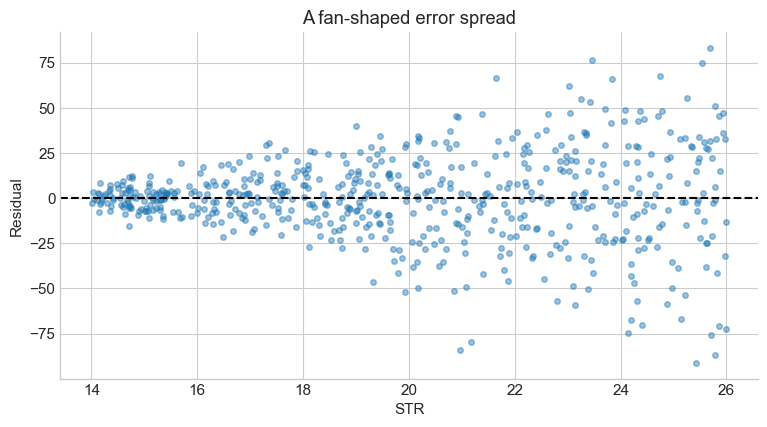

HC1 slope: -2.655; 95% large-sample CI: [-3.258, -2.052]
Two-sided large-sample p-value for H0: slope = 0: 6.258e-18


In [10]:
het_rng = np.random.default_rng(SEED+2)
xh = het_rng.uniform(14, 26, 600)
error_sd = 3 + 3*(xh-14)
yh = beta0+beta1*xh+het_rng.normal(0, error_sd)
het_model = sm.OLS(yh, sm.add_constant(xh)).fit()
robust_model = het_model.get_robustcov_results(cov_type='HC1', use_t=False)
np.testing.assert_allclose(het_model.params, robust_model.params)
display(pd.DataFrame({'Coefficient': het_model.params,
                      'Conventional SE': het_model.bse,
                      'HC1 robust SE': robust_model.bse}, index=['Intercept', 'STR']))
plt.scatter(xh, het_model.resid, s=16, alpha=.45)
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('STR'); plt.ylabel('Residual'); plt.title('A fan-shaped error spread'); plt.show()
ci = robust_model.conf_int(alpha=.05)[1]
print(f'HC1 slope: {robust_model.params[1]:.3f}; 95% large-sample CI: [{ci[0]:.3f}, {ci[1]:.3f}]')
print(f'Two-sided large-sample p-value for H0: slope = 0: {robust_model.pvalues[1]:.4g}')

## 6. Prediction: test on observations excluded from fitting
Fit on a training sample, then evaluate on a held-out test sample from the same population. Compare against predicting the **training mean**, never the test mean. Test RMSE uses the test sample size; it does not use $n-2$.

A model can predict well without its slope being causal. A change in the outcome process can break predictive performance even if the original fit was good. The final stress test introduces a known 20-point outcome shift; it is a controlled simulation, not an estimate from the held-out observations.

In [11]:
split_rng = np.random.default_rng(SEED+3)
order = split_rng.permutation(n)
train_idx, test_idx = order[:300], order[300:]
train = districts.iloc[train_idx]
test = districts.iloc[test_idx]
pred_model = sm.OLS(train.TestScore, sm.add_constant(train[['STR']])).fit()
test_pred = pred_model.predict(sm.add_constant(test[['STR']], has_constant='add'))
baseline_pred = np.full(len(test), train.TestScore.mean())

def prediction_metrics(actual, prediction):
    return {'RMSE': np.sqrt(np.mean((np.asarray(actual)-np.asarray(prediction))**2)),
            'MAE': np.mean(np.abs(np.asarray(actual)-np.asarray(prediction)))}

display(pd.DataFrame({
    'OLS held-out': prediction_metrics(test.TestScore, test_pred),
    'Training-mean baseline': prediction_metrics(test.TestScore, baseline_pred),
    'OLS after +20 outcome shift': prediction_metrics(test.TestScore+20, test_pred)
}).T)
new_x = pd.DataFrame({'const': [1., 1.], 'STR': [18., 24.]})
intervals = pred_model.get_prediction(new_x).summary_frame(alpha=.05)
intervals.insert(0, 'STR', [18., 24.])
display(intervals)
print(f'Training STR range: {train.STR.min():.2f} to {train.STR.max():.2f}')

,RMSE,MAE
OLS held-out,17.152,14.035
Training-mean baseline,18.107,14.367
OLS after +20 outcome shift,24.127,20.172


,STR,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,18.000,658.135,1.282,655.613,660.658,619.869,696.402
1,24.000,642.272,1.749,638.830,645.714,603.934,680.610


Training STR range: 14.05 to 25.95


`mean_ci_lower` and `mean_ci_upper` bound the estimated **conditional mean**. `obs_ci_lower` and `obs_ci_upper` are wider prediction intervals for a **new district**, including its unpredictable error. Here their conventional normal-error, homoskedastic assumptions match the simulated data-generating process. Avoid treating extrapolated predictions, such as STR = 0, as credible school forecasts.

## Try it yourself
1. Change the initial sample size from 420 to 840 and rerun all cells. Does the slope always move closer to -2.28 in a single realization? Why not?
2. Increase `sigma` while holding the true slope fixed. Explain what happens to R² and the uncertainty in the slope.
3. Set the resource effect `gamma` to zero. What happens to the omitted-variable term?
4. In `settings`, double the baseline sample size. What approximate factor should the slope SD change by? Confirm by simulation.
5. Explain why HC1 cannot repair the confounded assignment example.
6. Explain why a new-district prediction interval is wider than a confidence interval for the mean score.

### Instructor discussion notes
1. Precision improves on average, not necessarily in each realization.
2. More noise generally reduces R² and increases sampling uncertainty.
3. With no resource effect, resources no longer create omitted-variable bias in this model.
4. The large-sample SD changes by approximately $1/\sqrt{2}$.
5. HC1 estimates variance under heteroskedasticity; it does not restore zero conditional mean errors.
6. A new district has both parameter uncertainty and an individual error.

## Takeaways
OLS chooses the line with the smallest residual sum of squares. Its slope describes a fitted relationship; causal interpretation requires an argument about assignment and omitted factors. R², SER, and RMSE answer different questions about fit. Sampling uncertainty depends on sample size, regressor spread, and error variation. Prediction requires validation on new observations and attention to changes in their distribution.

**Source:** Qianwei Shen, *ECON 5105, Lesson 10: Linear Regression with One Regressor*, November 12, 2026, slides 1–58. This notebook uses original simulated examples; it does not distribute the lecture PDF or actual California school-district records.